# Comment Category Prediction

| | |
|---|---|
| **Problem** | Multi-class text classification (labels 0, 1, 2, 3) |
| **Metric** | Macro F1-Score |
| **Dataset** | 198K train rows, 102K test rows |
| **Final model** | LinearSVC |
| **Recorded Kaggle score** | 0.826 |

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from scipy.sparse import hstack, csr_matrix
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

sns.set_style('whitegrid')
RANDOM_STATE = 42

## 2. Data Loading


In [2]:
train= pd.read_csv('/kaggle/input/comment-category-prediction-challenge/train.csv')
test = pd.read_csv('/kaggle/input/comment-category-prediction-challenge/test.csv')

print('Train:', train.shape)
print('Test:',test.shape)

Train: (198000, 15)
Test: (102000, 14)


In [3]:
train.head()

,created_date,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,race,religion,gender,disability,comment,label
0,2024-01-18 08:43:57.397508+00:00,73,0,0,0,0,1,0,10,NaN,NaN,NaN,False,She might be a bright spot for a party keou on...,2
1,2024-03-24 21:43:11.490017+00:00,39,0,0,0,6,0,0,4,NaN,NaN,NaN,False,"Under Alaska law, a non-tribal member is not b...",0
2,2024-04-24 20:32:17.014931+00:00,31,0,1,1,0,0,0,10,NaN,NaN,NaN,False,in the future please spare me your strawman dr...,2
3,2023-05-28 22:00:14.214527+00:00,39,0,0,0,5,0,0,10,NaN,NaN,NaN,False,"PS: That should have been ""rot"" instead of ""co...",2
4,2023-09-09 23:12:05.689498+00:00,39,0,0,0,0,0,0,10,NaN,NaN,NaN,False,"Today, the confederate flag...tomorrow, the na...",2


## 3. Exploratory Data Analysis

Examine the data structure, class distribution, missing values, and feature characteristics before any modelling.

### 3.1 Basic Info
Basic info of data type of each column, missing values and label distribution.

In [5]:
print("Data Types")
print(train.dtypes)

Data Types
created_date    object
post_id          int64
emoticon_1       int64
emoticon_2       int64
emoticon_3       int64
upvote           int64
downvote         int64
if_1             int64
if_2             int64
race            object
religion        object
gender          object
disability        bool
comment         object
label            int64
dtype: object


In [6]:
print('Missing values')
print(train.isnull().sum())

Missing values
created_date         0
post_id              0
emoticon_1           0
emoticon_2           0
emoticon_3           0
upvote               0
downvote             0
if_1                 0
if_2                 0
race            145423
religion        145423
gender          145423
disability           0
comment              1
label                0
dtype: int64


In [7]:
print('Label Distribution')
print(train['label'].value_counts(normalize=True).round(4))

Label Distribution
label
0    0.5766
2    0.3154
1    0.0804
3    0.0276
Name: proportion, dtype: float64


### 3.2 Label Distribution

Two plots are used:
1. Bar chart to show the number of samples in each label.
2. Pie chart to show the percentage of data in each label.


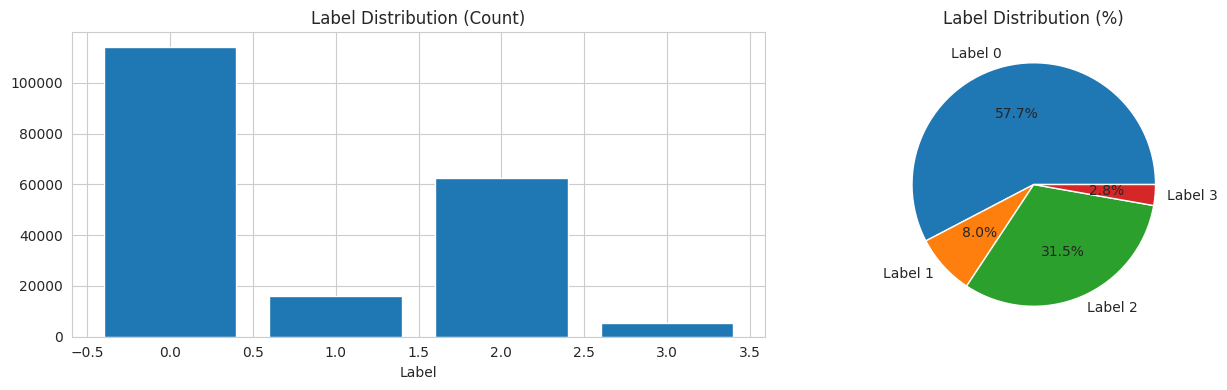

In [16]:
fig,axes = plt.subplots(1,2,figsize=(14, 4))

counts = train['label'].value_counts().sort_index()
axes[0].bar(counts.index,counts.values)
axes[0].set_title('Label Distribution (Count)')
axes[0].set_xlabel('Label')

#plot 2- percentage of each label
percentage = train['label'].value_counts(normalize=True).sort_index()*100
axes[1].pie(percentage, labels=[f'Label {i}' for i in percentage.index], autopct='%1.1f%%')
axes[1].set_title('Label Distribution (%)')

plt.tight_layout()
plt.show()

#### Key Insight
The dataset is heavily imbalanced. Label 0 dominates with 57.7% of all 
samples while Label 3 has only 2.8%. This means accuracy is a misleading 
metric here i.e, a model that always predicts Label 0 would still get 57.7% 
accuracy without learning anything useful. This is why we chose Macro F1 
as our metric, which treats all 4 classes equally. 

### 3.3 Comment Length

Plotting a histogram to check comment length distribution, and a bar chart for avg comment length in each label.

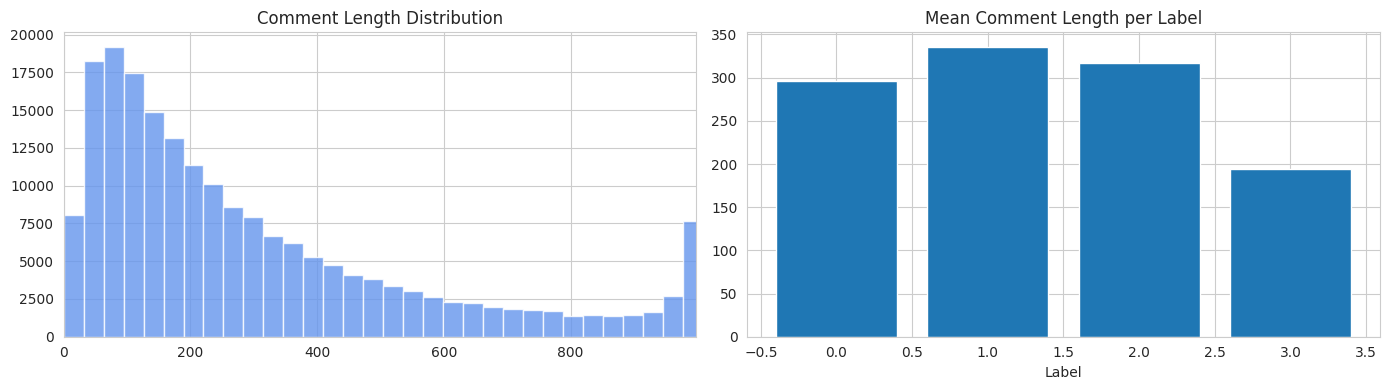

          count   mean    std  min    25%    50%    75%     max
label                                                          
0      114173.0  295.9  269.6  0.0   93.0  199.0  411.0  1892.0
1       15918.0  335.7  267.5  6.0  129.0  246.0  465.0  1006.0
2       62440.0  316.9  262.8  3.0  117.0  232.0  437.0  1006.0
3        5469.0  194.2  194.3  7.0   68.0  128.0  245.0  1005.0


In [9]:
train['comment_len'] = train['comment'].fillna('').str.len()
test['comment_len'] = test['comment'].str.len()

fig,axes = plt.subplots(1,2, figsize=(14,4))

#histogram
axes[0].hist(train['comment_len'], bins=60, color='cornflowerblue', alpha=0.8)
axes[0].set_title('Comment Length Distribution')
axes[0].set_xlim(0, train['comment_len'].quantile(0.99))

#bar chart
mean_len = train.groupby('label')['comment_len'].mean()
axes[1].bar(mean_len.index, mean_len.values)
axes[1].set_title('Mean Comment Length per Label')
axes[1].set_xlabel('Label')

plt.tight_layout()
plt.show()

print(train.groupby('label')['comment_len'].describe().round(1))

#### Key Insight
Label 3 comments are noticeably shorter (mean 194 characters) compared 
to Label 1 (336 characters). We kept `comment_len` and `word_count` as explicit features 
in the feature-engineering step.


### 3.4 Numeric Features

Four plots are used:
1. Box plot to inspect outliers.
2. Correlation heatmap.
3. Bar chart for mean upvotes per label.
4. Skewness bar chart.


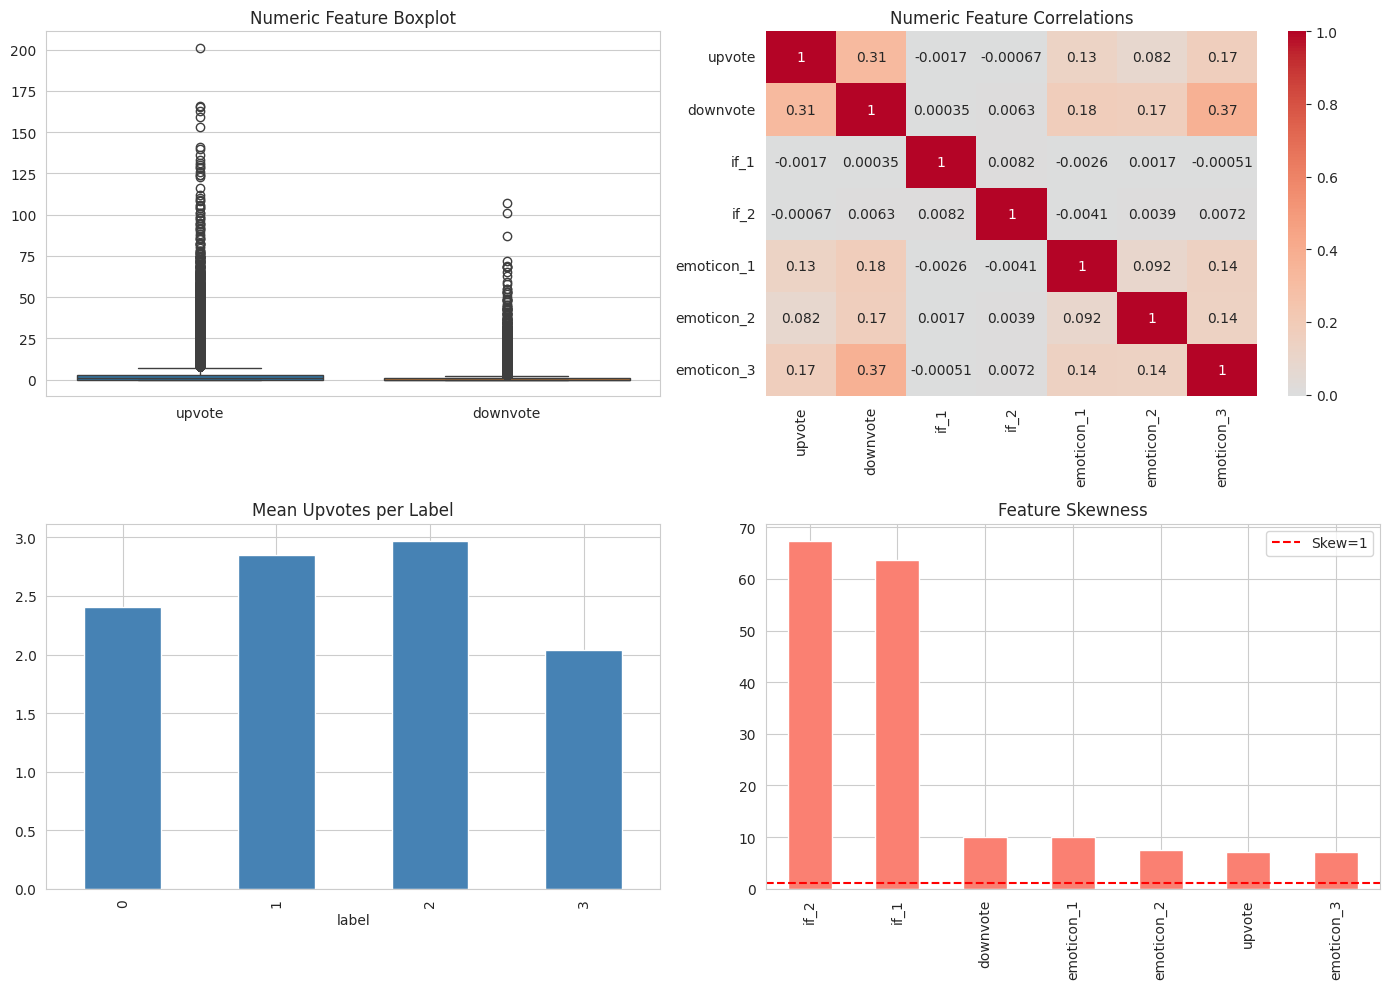

if_2          67.32
if_1          63.70
downvote      10.06
emoticon_1     9.98
emoticon_2     7.56
upvote         7.10
emoticon_3     7.06
dtype: float64


In [24]:
num_cols = ['upvote','downvote','if_1','if_2','emoticon_1','emoticon_2','emoticon_3']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# box plot
sns.boxplot(data=train[['upvote','downvote']], ax=axes[0,0])
axes[0,0].set_title('Numeric Feature Boxplot')

# correalation heatmap
correlation = train[num_cols].corr()
sns.heatmap(correlation, annot=True,cmap='coolwarm', center=0, ax=axes[0,1])
axes[0,1].set_title('Numeric Feature Correlations')

# mean upvotes per label
mean_upvotes = train.groupby('label')['upvote'].mean()
mean_upvotes.plot(kind='bar', ax=axes[1,0], color='steelblue')
axes[1,0].set_title('Mean Upvotes per Label')

#skewness bar chart
skew = train[num_cols].skew().abs().sort_values(ascending=False)
skew.plot(kind='bar', ax=axes[1,1], color='salmon')
axes[1,1].axhline(y=1, color='red', linestyle='--', label='Skew=1')
axes[1,1].set_title('Feature Skewness')
axes[1,1].legend()

plt.tight_layout()
plt.show()
print(skew.round(2))

#### Key Insight
1. upvote and downvote have many outliers — `log_upvote` and `log_downvote` features created.
2. emoticon_1/2/3 are somewhat correlated — combined into `emoticon_sum` feature.
3. Label 1 gets most upvotes, Label 3 gets least
4. `if_1` and `if_2` have extreme skewness (63.7, 67.3) — `log1p` transform applied 
   to fix this.

### 3.5 Categorical & Missing Values

Checking missing values in race, religion and gender column.

In [25]:
cat_cols = ['gender', 'race', 'religion']

for col in cat_cols:
    missing = train[col].isnull().sum()
    percent = round(missing / len(train) * 100, 1)
    print(f'{col}: {missing:,} ({percent}%)')

gender: 145,423 (73.4%)
race: 145,423 (73.4%)
religion: 145,423 (73.4%)


Disability column info

In [29]:
train['disability'].value_counts()

disability
False    195257
True       2743
Name: count, dtype: int64

#### Key Insight
race, religion, and gender columns have ~73% missing values.

### 3.6 Statistical Summary

In [27]:
print('Numeric Feature Statistics')
print(train[num_cols].describe().round(2))

Numeric Feature Statistics
          upvote   downvote       if_1       if_2  emoticon_1  emoticon_2  \
count  198000.00  198000.00  198000.00  198000.00   198000.00   198000.00   
mean        2.61       0.67       1.91       7.96        0.28        0.05   
std         5.05       2.04      25.64      14.84        1.02        0.26   
min         0.00       0.00       0.00       3.00        0.00        0.00   
25%         0.00       0.00       0.00       4.00        0.00        0.00   
50%         1.00       0.00       0.00       6.00        0.00        0.00   
75%         3.00       1.00       4.00      10.00        0.00        0.00   
max       201.00     107.00    1860.00    1833.00       47.00       11.00   

       emoticon_3  
count   198000.00  
mean         0.12  
std          0.48  
min          0.00  
25%          0.00  
50%          0.00  
75%          0.00  
max         17.00  


#### Key Insight

1. Numeric features show significant skewness — upvote mean (2.61) is much higher than median (1.0), confirming outliers pull the average up.

2. `if_1 max = 1860` and `if_2 min = 3` show extreme outliers.


## 4. Preprocessing & Feature Engineering
Prepare the data in four steps:
1. Fill missing values
2. Clean text
3. Engineer new numeric features
4. Build the feature matrix (TF-IDF + numeric)

### 4.1 Missing Value Imputation

The single training row with a missing comment is dropped because removing one row from 198,000 has negligible impact on model training.

Missing categorical values are filled consistently in both train and test sets:
- race, religion, gender: `'unknown'` (~73% missing; not used as model features)
- disability: boolean converted to integer 0/1


In [31]:
train = train.dropna(subset=['comment'])

for df in [train, test]:
    df['race'] = df['race'].fillna('unknown')
    df['religion'] = df['religion'].fillna('unknown')
    df['gender'] = df['gender'].fillna('unknown')
    df['disability'] = df['disability'].astype(int)

print('Missing values remaining:', train.isnull().sum().sum())

Missing values remaining: 0


### 4.2 Text Cleaning

Did this in four steps:

1. Lowercase text
2. Replace URLs with a token (url)
3. Remove special characters
4. Collapse extra whitespace.

In [32]:
def clean_text(series):
    s = series.astype(str).str.lower()
    s = s.str.replace(r'http\S+|www\S+|https\S+',' url ',regex=True)
    s = s.str.replace(r'[^a-zA-Z0-9\s]',' ', regex=True)
    s = s.str.replace(r'\s+',' ', regex=True)
    return s.str.strip()

train['comment_clean'] = clean_text(train['comment'])
test['comment_clean'] = clean_text(test['comment'])

print('BEFORE:', train['comment'].iloc[0])
print('AFTER:', train['comment_clean'].iloc[0])

BEFORE: She might be a bright spot for a party keou on Oahu dominated by greedy criminals or ethically challenged individuals.
AFTER: she might be a bright spot for a party keou on oahu dominated by greedy criminals or ethically challenged individuals


### 4.3 Feature Engineering

We derive additional signals from existing columns:


| Feature | Calculation | Why |
|---|---|---|
| `word_count` | number of words in comment | longer comments may belong to different categories |
| `avg_word_len` | comment_len / word_count | proxy for vocabulary complexity |
| `upvote_ratio` | upvote / (upvote + downvote + 1) | 100 upvote 0 downvote vs 100 upvote 99 downvote — raw count same but quality different |
| `vote_total` | upvote + downvote | total engagement regardless of direction |
| `emoticon_sum` | emoticon_1 + emoticon_2 + emoticon_3 | total emoticon usage |
| `log_if_1`, `log_if_2` | log1p(if_1), log1p(if_2) | fixes extreme skewness (63.7, 67.3) |
| `log_upvote`, `log_downvote` | log1p(upvote/downvote) | reduces outlier dominance |
| `is_weekend` | 1 if Sat/Sun else 0 | comment behaviour may differ on weekends |
| `hour` | hour from created_date | time-of-day patterns in comments |

In [ ]:
def engineer_features(df):

    df['word_count']= df['comment_clean'].str.split().str.len()
    df['comment_len']= df['comment_clean'].str.len()
    df['avg_word_len'] = df['comment_len']/(df['word_count'] + 1)
    df['upvote_ratio'] = df['upvote'] / (df['upvote'] + df['downvote'] + 1)
    df['vote_total'] = df['upvote'] + df['downvote']
    df['emoticon_sum']= df['emoticon_1'] + df['emoticon_2'] + df['emoticon_3']
    df['log_if_1'] =np.log1p(df['if_1'])
    df['log_if_2'] =np.log1p(df['if_2'])
    df['log_upvote'] = np.log1p(df['upvote'])
    df['log_downvote'] = np.log1p(df['downvote'])
    df['created_date'] = pd.to_datetime(df['created_date'])
    df['is_weekend'] = (df['created_date'].dt.weekday>= 5).astype(int)
    df['hour']= df['created_date'].dt.hour
    return df

train = engineer_features(train)
test = engineer_features(test)
print('Train shape:', train.shape)

### Output

>Train shape: (197999, 28)

### Why Feature Engineering
Raw numeric columns like upvote and downvote don't fully capture the 
engagement pattern. For example, a comment with 100 upvotes and 0 downvotes 
is very different from one with 100 upvotes and 99 downvotes — but the raw 
upvote count is the same. upvote_ratio captures this distinction.

Log transforms on if_1, if_2, upvote, downvote fix their extreme skewness, 
helping models like Logistic Regression and LinearSVC learn more effectively.

Temporal features (is_weekend, hour) capture the fact that comment behavior 
may differ at different times of day or week.

### 4.4 Train-Validation Split

The usable training data is split 80/20 into training and validation sets. The model trains on `X_train` and is evaluated on `X_val`.

We use `stratify=y` to preserve class proportions in both splits. Without stratification, the validation set could contain too few Label 3 samples (only 2.8% of the data), making the Macro F1 estimate less reliable.


In [ ]:
numeric_features = ['upvote', 'downvote', 'if_1', 'if_2','emoticon_1', 'emoticon_2', 'emoticon_3',
    'comment_len', 'word_count', 'avg_word_len','upvote_ratio', 'vote_total', 'emoticon_sum',
    'log_if_1', 'log_if_2', 'log_upvote', 'log_downvote','is_weekend', 'hour', 'disability']

X = train.copy()
y = train['label']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape[0])
print("Val:", X_val.shape[0])

print('Val class balance:')
print((y_val.value_counts(normalize=True) * 100).round(1))

Train: 158,399 | Val: 39,600

Val class balance:

    label
    0    57.7
    2    31.5
    1     8.0
    3     2.8
    Name: proportion, dtype: float64

### 4.5 TF-IDF Vectorization

Now applying word level and character level TF-IDF

**Word-level TF-IDF (60K features):**
- max_features=60000 — top 60K most useful words
- ngram_range=(1,3) — single words, pairs, triplets
- min_df=2 — ignore words appearing in only 1 comment
- sublinear_tf=True — uses log(TF) instead of raw TF, prevents common words dominating
- analyzer='word' — word level features

**Character-level TF-IDF (40K features):**
- max_features=40000 — top 40K char sequences
- analyzer='char_wb' — character sequences respecting word boundaries
- ngram_range=(3,5) — 3 to 5 char sequences, captures 'un-', '-ing', misspellings
- min_df=3 — stricter than word TF-IDF, char sequences noisier

In [ ]:
word_tfidf = TfidfVectorizer(
    max_features=60000, 
    ngram_range=(1, 3),
    min_df=2,
    sublinear_tf=True,
    strip_accents='unicode', 
    analyzer='word'
)

X_train_word = word_tfidf.fit_transform(X_train['comment_clean'])
X_val_word = word_tfidf.transform(X_val['comment_clean'])
print('Word TF-IDF:', X_train_word.shape)

char_tfidf = TfidfVectorizer(
    max_features=40000,
    analyzer='char_wb',
    ngram_range=(3, 5),
    min_df=3,
    sublinear_tf=True
)

X_train_char = char_tfidf.fit_transform(X_train['comment_clean'])
X_val_char = char_tfidf.transform(X_val['comment_clean'])
print('Char TF-IDF:', X_train_char.shape)

### Output
> Word TF-IDF: (158399, 60000)

> Char TF-IDF: (158399, 40000)

#### Why Two Types of TF-IDF
Word-level TF-IDF captures whole words and phrases. Character-level TF-IDF 
captures sub-word patterns — prefixes like 'un-', suffixes like '-ing', and 
even misspellings. Together they complement each other.

Fitting TF-IDF only on training data to prevent data leakage. If we fit on 
all data, test word frequencies would influence IDF values — giving the model 
an unfair advantage.

Final feature matrix: 60K word + 40K char + 20 numeric = 100,020 features.

### 4.6 Numeric Scaling & Feature Combination

**StandardScaler:**
- Transforms numeric features to mean=0, std=1
- Without scaling, upvote (0-200) would dominate is_weekend (0-1)
- fit only on train, transform val and test — prevent data leakage
- TF-IDF not scaled — already in 0-1 range

**csr_matrix:**
- Scaler returns dense matrix — convert to sparse for hstack
- Sparse format stores only non-zero values — saves memory

**hstack (scipy.sparse):**
- Combines word TF-IDF + char TF-IDF + numeric horizontally
- 60,000 + 40,000 + 20 = 100,020 features per comment

In [ ]:
scaler = StandardScaler()
X_train_num = csr_matrix(scaler.fit_transform(X_train[numeric_features]))
X_val_num = csr_matrix(scaler.transform(X_val[numeric_features]))

# hstack combines sparse matrices horizontally without densifying them
X_train_final = hstack([X_train_word, X_train_char, X_train_num])
X_val_final = hstack([X_val_word,X_val_char, X_val_num])

print('Final train:', X_train_final.shape)
print('Final val:', X_val_final.shape)

### Output

> Final train: (158399, 100020)

> Final val: (39600, 100020)


## 5. Model Training & Comparison

Training three models covering different approaches:
- **Logistic Regression** — linear, probabilistic, cross-entropy/log-loss objective
- **LinearSVC** — linear, margin-based, squared-hinge loss (scikit-learn default)  
- **Naive Bayes** — probabilistic, generative baseline using word TF-IDF


### Model 1 — Logistic Regression

A linear classifier that learns a weight for each feature. For multiclass classification, it estimates class scores/probabilities and predicts the class with the highest probability.

**Parameters:**
- `C=5.0` — inverse regularization strength; higher C means weaker regularization
- `max_iter=2000` — allows sufficient iterations for the high-dimensional sparse feature space
- `class_weight='balanced'` — gives greater weight to minority classes
- `solver='lbfgs'` — optimization solver used for training
- Objective: multiclass log-loss / cross-entropy


In [ ]:
lr = LogisticRegression(
    C=5.0, max_iter=2000,
    class_weight='balanced',
    solver='lbfgs',
    random_state=RANDOM_STATE
)

lr.fit(X_train_final, y_train)
lr_preds = lr.predict(X_val_final)
lr_f1  = f1_score(y_val, lr_preds, average='macro')
lr_acc = accuracy_score(y_val, lr_preds)
print(classification_report(y_val, lr_preds))
print(f'Macro F1: {lr_f1:.4f} | Accuracy: {lr_acc:.4f}')

### Output
              
              precision    recall  f1-score   support

           0       0.98      0.94      0.96     22834
           1       0.72      0.82      0.77      3184
           2       0.87      0.89      0.88     12488
           3       0.59      0.72      0.65      1094

    accuracy                           0.91     39600
    macro avg       0.79      0.84      0.81     39600
    weighted avg       0.91      0.91      0.91     39600

>Macro F1: 0.8120  |  Accuracy: 0.9060

### Model 2 — LinearSVC

A linear Support Vector Classifier that learns decision boundaries with a maximum-margin objective. In multiclass classification, scikit-learn uses a one-vs-rest strategy.

**Parameters:**
- `C=0.5` — used for the initial comparison; best `C=0.1` was found later with GridSearchCV
- `class_weight='balanced'` — increases the penalty associated with minority classes
- `max_iter=2000` — maximum optimization iterations
- Loss function: **squared hinge** (the default for `LinearSVC`)


In [ ]:
svm = LinearSVC(
    C=0.5, 
    class_weight='balanced',
    max_iter=2000, random_state=RANDOM_STATE
)

svm.fit(X_train_final, y_train)
svm_preds = svm.predict(X_val_final)
svm_f1  = f1_score(y_val, svm_preds, average='macro')
svm_acc = accuracy_score(y_val, svm_preds)

print(classification_report(y_val, svm_preds))
print(f'Macro F1: {svm_f1:.4f} | Accuracy: {svm_acc:.4f}')

### Output
    
                precision    recall  f1-score   support

           0       0.98      0.94      0.96     22834
           1       0.74      0.81      0.77      3184
           2       0.87      0.90      0.88     12488
           3       0.65      0.66      0.65      1094

    accuracy                            0.91     39600
    macro avg       0.81      0.83      0.82     39600
    weighted avg    0.91      0.91      0.91     39600

>Macro F1: 0.8173  |  Accuracy: 0.9108

### Model 3 — Naive Bayes

Multinomial Naive Bayes is used as a lightweight probabilistic text-classification baseline.

**Parameters:**
- `alpha=0.1` — additive (Laplace/Lidstone) smoothing to avoid zero-probability problems
- This baseline is trained on **word TF-IDF only**. The standardized numeric features can contain negative values, which are not suitable for `MultinomialNB`, so they are excluded from this baseline.


In [ ]:
nb = MultinomialNB(alpha=0.1)

nb.fit(X_train_word, y_train)
nb_preds = nb.predict(X_val_word)

nb_f1  = f1_score(y_val, nb_preds, average='macro')
nb_acc = accuracy_score(y_val, nb_preds)

print(classification_report(y_val, nb_preds))
print(f'Macro F1: {nb_f1:.4f} | Accuracy: {nb_acc:.4f}')

### Output
              
              precision    recall  f1-score   support

           0       0.72      0.88      0.80     22834
           1       0.67      0.42      0.52      3184
           2       0.70      0.54      0.61     12488
           3       0.73      0.13      0.23      1094

    accuracy                           0.72     39600
    macro avg       0.71     0.49      0.54     39600
    weighted avg    0.71     0.72      0.70     39600

>Macro F1: 0.5362  |  Accuracy: 0.7159

### Model Comparison

We compare all three models on validation macro F1.

              Model  Val Macro F1  Val Accuracy
          LinearSVC        0.8167        0.9111
Logistic Regression        0.8086        0.9053
        Naive Bayes        0.5375        0.7152


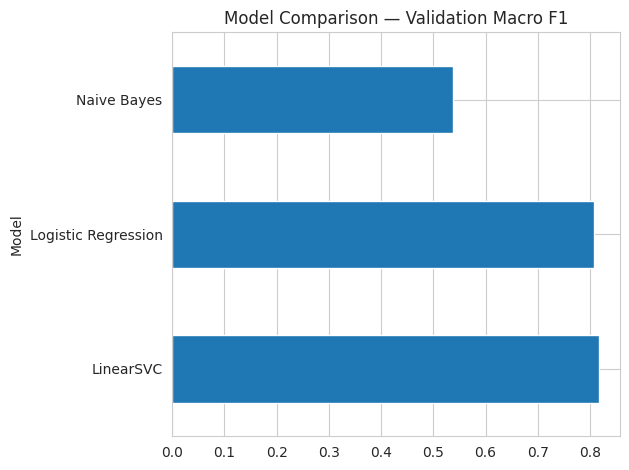

In [33]:
results = [
    {'Model':'LinearSVC','Val Macro F1': 0.8167,'Val Accuracy': 0.9111},
    {'Model':'Logistic Regression','Val Macro F1': 0.8086,'Val Accuracy': 0.9053},
    {'Model':'Naive Bayes','Val Macro F1': 0.5375,'Val Accuracy': 0.7152},
]
comparison = pd.DataFrame(results).sort_values('Val Macro F1', ascending=False)
print(comparison.to_string(index=False))

comparison.plot(x='Model', y='Val Macro F1', kind='barh', legend=False)
plt.title('Model Comparison — Validation Macro F1')
plt.tight_layout()
plt.show()

### Model Comparison Insights
LinearSVC achieved the highest validation Macro F1 in the recorded comparison, followed by Logistic Regression. Naive Bayes scored lowest.

Both LinearSVC and Logistic Regression are linear models suited to high-dimensional sparse text features. LinearSVC was selected as the final model.

The Naive Bayes baseline used only word TF-IDF, while the linear models used the combined word TF-IDF, character TF-IDF, and numeric feature matrix.

> The saved notebook preserves outputs from the original experimentation process. Some intermediate result blocks were recorded at different experiment stages and therefore differ slightly, but they agree on the model ranking: **LinearSVC > Logistic Regression > Naive Bayes**.


### Confusion Matrix

The confusion matrix shows how predictions are distributed across the four labels.

- Diagonal cells = correct predictions
- Off-diagonal cells = classification errors
- Darker cells = more predictions in that cell


In [ ]:
cm = confusion_matrix(y_val, svm_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0,1,2,3])
fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion Matrix — LinearSVC')
plt.tight_layout()
plt.show()

### Output

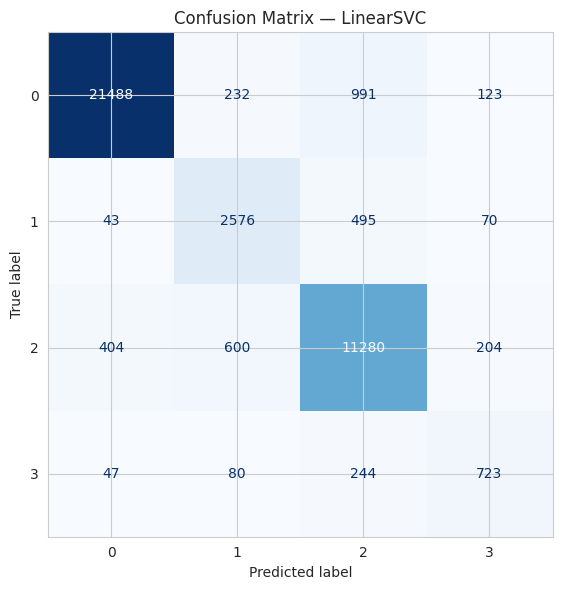

#### Insights
Confusion matrix shows model performance is related to training 
data size:

- Label 0 (57.7% data) — 21,498 correct, least confusion
- Label 2 (31.5% data) — 11,266 correct, some confusion with Label 1
- Label 1 (8.0% data)  — 2,580 correct, confused with Label 2
- Label 3 (2.8% data)  — 729 correct, most confused — least training data

Label 1 and Label 2 are frequently confused with each other — suggesting 
these two categories have similar comment patterns. class_weight='balanced' 
helped minority classes but could not fully compensate for lack of data.

## 6. Hyperparameter Tuning — LinearSVC

We use GridSearchCV with 3-fold cross validation to tune the C parameter 
for LinearSVC.

**GridSearchCV:**
- Tests every combination in param_grid
- cv=3 — splits training data into 3 parts, trains on 2, 
  evaluates on 1, rotates 3 times, takes average score
- scoring='f1_macro' — optimizes same metric as Kaggle
- Total fits = 4 C values x 3 folds = 12 model fits

**C parameter:**
- Small C = strong regularization = wider margin = better generalization
- Large C = weak regularization = risk of overfitting

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {'C': [0.05, 0.1, 0.3, 0.5]}

grid = GridSearchCV(
    LinearSVC(class_weight='balanced',
    max_iter=2000, random_state=RANDOM_STATE),
    param_grid, cv=3, 
    scoring='f1_macro', 
    n_jobs=-1
)
grid.fit(X_train_final, y_train)

cv_results = pd.DataFrame(grid.cv_results_)
print(cv_results[['param_C','mean_test_score']].round(4))

best_C_svc = grid.best_params_['C']
print('Best C:',best_C_svc)
print('Best F1:',round(grid.best_score_, 4))

### Output

       param_C  mean_test_score
    0     0.05           0.8206
    1     0.10           0.8230
    2     0.30           0.8204
    3     0.50           0.8161
    Best C: 0.1
    Best F1: 0.823

### Tuning Insight
`C=0.1` produced the best mean Macro F1 among the tested values.

Within this search range, stronger regularization performed better than the larger C values.

GridSearchCV with 3-fold cross-validation was used to obtain a more stable estimate by averaging performance across three folds.


## 7. Final Submission

After validation and tuning, the final pipeline is refit on **all usable training rows (197,999 of the original 198,000)**. The one excluded row had a missing comment.

Word TF-IDF, character TF-IDF, and the numeric scaler are fit again on the full usable training set before generating predictions for the test set.


In [ ]:
word_tfidf_full = TfidfVectorizer(
    max_features=60000,
    ngram_range=(1, 3),
    min_df=2, sublinear_tf=True,
    strip_accents='unicode',
    analyzer='word'
)

X_full_word = word_tfidf_full.fit_transform(train['comment_clean'])
X_test_word_full = word_tfidf_full.transform(test['comment_clean'])

char_tfidf_full = TfidfVectorizer(
    max_features=40000, 
    analyzer='char_wb',
    ngram_range=(3, 5),
    min_df=3,
    sublinear_tf=True
)

X_full_char= char_tfidf_full.fit_transform(train['comment_clean'])
X_test_char_full = char_tfidf_full.transform(test['comment_clean'])


scaler_full = StandardScaler()
X_full_num = csr_matrix(scaler_full.fit_transform(train[numeric_features]))
X_test_num_full = csr_matrix(scaler_full.transform(test[numeric_features]))

X_full_final = hstack([X_full_word, X_full_char, X_full_num])
X_test_final_full = hstack([X_test_word_full, X_test_char_full, X_test_num_full])

print('Full train:', X_full_final.shape)
print('Test:', X_test_final_full.shape)

>Full train: (197999, 100020)

>Test: (102000, 100020)

### Why Retrain on Full Usable Data

After model selection, the validation holdout is no longer required for choosing the final model. The pipeline is therefore refit on all **197,999 usable training rows**.

Benefits:
- Uses the full available training signal
- Improves vocabulary coverage
- Fits IDF values and numeric scaling parameters using all usable training examples


### 7.2 Train Final Model

Train the final LinearSVC with the selected `C=0.1` on all **197,999 usable training rows**.


In [ ]:
final_model = LinearSVC(
    C=best_C_svc,                   
    class_weight='balanced',
    max_iter=2000,
    random_state=RANDOM_STATE
)

final_model.fit(X_full_final, train['label'])

### Generate Submission

We load `Sample.csv` and overwrite the `label` column with predictions. 

In [ ]:
test_preds = final_model.predict(X_test_final_full)

submission = pd.read_csv('/kaggle/input/comment-category-prediction-challenge/Sample.csv')
submission['label'] = test_preds.astype(int)
submission.to_csv('submission.csv', index=False)